<a href="https://colab.research.google.com/github/aaditi-kapre/pandas/blob/main/wakeWordDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install python_speech_features

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
  Preparing metadata (setup.py) ... done
  Created wheel for python_speech_features: filename=python_speech_features-0.6-py3-none-any.whl size=5889 sha256=9ddd5c8fd696dde77ccd314df3008e22de189e7117e6d2ad28a4179eba358ac5
  Stored in directory: /root/.cache/pip/wheels/5b/60/87/28af2605138deac93d162904df42b6fdda1dab9b8757c62aa3
Successfully built python_speech_features


In [ ]:
from os import listdir
from os.path import isdir, join
import librosa
import random
import numpy as np
import matplotlib.pyplot as plt
import python_speech_features

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Dataset path and view possible targets
dataset_path = '/content/drive/MyDrive/Wake_Word_Detection/Dataset/speech_commands_dataset'
for name in listdir(dataset_path):
    if isdir(join(dataset_path, name)):
        print(name)

stop
sheila
follow
happy


In [ ]:
# Create an all targets list
all_targets = [name for name in listdir(dataset_path) if isdir(join(dataset_path, name))]
print(all_targets)

['stop', 'sheila', 'follow', 'happy']


In [ ]:
# Leave off background noise set
# all_targets.remove('_background_noise_')
# print(all_targets)

ValueError: ignored

In [ ]:
# See how many files are in each
num_samples = 0
for target in all_targets:
    print(len(listdir(join(dataset_path, target))))
    num_samples += len(listdir(join(dataset_path, target)))
print('Total samples:', num_samples)

3872
2022
1579
2054
Total samples: 9527


In [ ]:
# Settings
target_list = all_targets
feature_sets_file = 'all_targets_mfcc_sets.npz'
perc_keep_samples = 1.0 # 1.0 is keep all samples
val_ratio = 0.1
test_ratio = 0.1
sample_rate = 8000
num_mfcc = 16
len_mfcc = 16

In [ ]:
# Create list of filenames along with ground truth vector (y)
filenames = []
y = []
for index, target in enumerate(target_list):
    print(join(dataset_path, target))
    filenames.append(listdir(join(dataset_path, target)))
    y.append(np.ones(len(filenames[index])) * index)

/content/drive/MyDrive/Wake_Word_Detection/Dataset/speech_commands_dataset/stop
/content/drive/MyDrive/Wake_Word_Detection/Dataset/speech_commands_dataset/sheila
/content/drive/MyDrive/Wake_Word_Detection/Dataset/speech_commands_dataset/follow
/content/drive/MyDrive/Wake_Word_Detection/Dataset/speech_commands_dataset/happy


In [ ]:
# Check ground truth Y vector
print(y)
for item in y:
    print(len(item))

[array([0., 0., 0., ..., 0., 0., 0.]), array([1., 1., 1., ..., 1., 1., 1.]), array([2., 2., 2., ..., 2., 2., 2.]), array([3., 3., 3., ..., 3., 3., 3.])]
3872
2022
1579
2054


In [ ]:
# Flatten filename and y vectors
filenames = [item for sublist in filenames for item in sublist]
y = [item for sublist in y for item in sublist]

In [ ]:
# Associate filenames with true output and shuffle
filenames_y = list(zip(filenames, y))
random.shuffle(filenames_y)
filenames, y = zip(*filenames_y)

In [ ]:
# Only keep the specified number of samples (shorter extraction/training)
print(len(filenames))
filenames = filenames[:int(len(filenames) * perc_keep_samples)]
print(len(filenames))

9527
9527


In [ ]:
# Calculate validation and test set sizes
val_set_size = int(len(filenames) * val_ratio)
test_set_size = int(len(filenames) * test_ratio)

In [ ]:
# Break dataset apart into train, validation, and test sets
filenames_val = filenames[:val_set_size]
filenames_test = filenames[val_set_size:(val_set_size + test_set_size)]
filenames_train = filenames[(val_set_size + test_set_size):]

In [ ]:
# Break y apart into train, validation, and test sets
y_orig_val = y[:val_set_size]
y_orig_test = y[val_set_size:(val_set_size + test_set_size)]
y_orig_train = y[(val_set_size + test_set_size):]

In [ ]:
# Function: Create MFCC from given path
def calc_mfcc(path):

    # Load wavefile
    signal, fs = librosa.load(path, sr=sample_rate)

    # Create MFCCs from sound clip
    mfccs = python_speech_features.base.mfcc(signal,
                                            samplerate=fs,
                                            winlen=0.256,
                                            winstep=0.050,
                                            numcep=num_mfcc,
                                            nfilt=26,
                                            nfft=2048,
                                            preemph=0.0,
                                            ceplifter=0,
                                            appendEnergy=False,
                                            winfunc=np.hanning)
    return mfccs.transpose()

In [ ]:
# TEST: Construct test set by computing MFCC of each WAV file
prob_cnt = 0
x_test = []
y_test = []
for index, filename in enumerate(filenames_train):

    # Stop after 500
    if index >= 500:
        break

    # Create path from given filename and target item
    path = join(dataset_path, target_list[int(y_orig_train[index])],
                filename)

    # Create MFCCs
    mfccs = calc_mfcc(path)

    if mfccs.shape[1] == len_mfcc:
        x_test.append(mfccs)
        y_test.append(y_orig_train[index])
    else:
        print('Dropped:', index, mfccs.shape)
        prob_cnt += 1


Dropped: 5 (16, 12)
Dropped: 26 (16, 11)
Dropped: 42 (16, 15)
Dropped: 52 (16, 14)
Dropped: 64 (16, 8)
Dropped: 69 (16, 13)
Dropped: 92 (16, 13)
Dropped: 98 (16, 14)
Dropped: 107 (16, 14)
Dropped: 113 (16, 14)
Dropped: 118 (16, 14)
Dropped: 124 (16, 13)
Dropped: 143 (16, 10)
Dropped: 144 (16, 13)
Dropped: 145 (16, 14)
Dropped: 174 (16, 12)
Dropped: 190 (16, 11)
Dropped: 192 (16, 13)
Dropped: 205 (16, 10)
Dropped: 221 (16, 14)
Dropped: 235 (16, 11)
Dropped: 247 (16, 13)
Dropped: 255 (16, 15)
Dropped: 284 (16, 15)
Dropped: 290 (16, 15)
Dropped: 292 (16, 8)
Dropped: 309 (16, 10)
Dropped: 310 (16, 12)
Dropped: 335 (16, 13)
Dropped: 336 (16, 15)
Dropped: 372 (16, 11)
Dropped: 379 (16, 13)
Dropped: 380 (16, 13)
Dropped: 406 (16, 13)
Dropped: 428 (16, 9)
Dropped: 439 (16, 12)
Dropped: 473 (16, 12)
Dropped: 478 (16, 12)
Dropped: 488 (16, 14)
Dropped: 499 (16, 7)


In [ ]:
print('% of problematic samples:', prob_cnt / 500)

% of problematic samples: 0.08


In [ ]:
!pip install PyObjC

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
MFCCs: [[-3.22263812e+01 -2.50311441e+01 -2.18384358e+01 -2.19211620e+01
  -2.23224730e+01 -1.98699201e+01 -1.89732264e+01 -2.00313142e+01
  -2.14410139e+01 -2.12402922e+01 -2.28613765e+01 -2.60123988e+01
  -3.23437281e+01 -4.23700471e+01 -4.92359607e+01 -4.99768368e+01]
 [-1.34941789e+00  3.51177857e+00  5.73493186e+00  6.55727103e+00
   7.08404222e+00  6.96066711e+00  8.09821348e+00  1.10614423e+01
   1.32426753e+01  1.27418582e+01  1.28950853e+01  1.29834067e+01
   1.20237431e+01  8.37866133e+00  4.22745999e+00  3.50977298e+00]
 [ 6.18641103e+00  6.56546076e+00  5.18610779e+00  4.16270807e+00
   3.09413540e+00  1.09304375e+00 -1.48143011e+00 -4.06927391e+00
  -5.86847667e+00 -6.75184853e+00 -6.71829238e+00 -6.44614016e+00
  -5.66110805e+00 -3.70285571e+00 -1.49800082e+00 -1.63180284e+00]
 [-1.56664285e+00 -6.88456696e-01 -1.14819891e-01 -4.54055963e-01
  -4.47193149e-01  6.03846776e-01

CalledProcessError: ignored

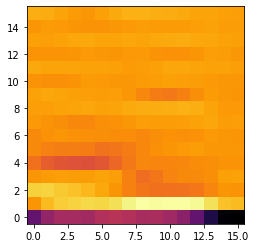

In [ ]:
# TEST: Test shorter MFCC
!pip install playsound
from playsound import playsound

idx = 13

# Create path from given filename and target item
path = join(dataset_path, target_list[int(y_orig_train[idx])],
            filenames_train[idx])

# Create MFCCs
mfccs = calc_mfcc(path)
print("MFCCs:", mfccs)

# Plot MFCC
fig = plt.figure()
plt.imshow(mfccs, cmap='inferno', origin='lower')

# TEST: Play problem sounds
print(target_list[int(y_orig_train[idx])])
playsound(path)

In [ ]:
# Function: Create MFCCs, keeping only ones of desired length
def extract_features(in_files, in_y):
    prob_cnt = 0
    out_x = []
    out_y = []

    for index, filename in enumerate(in_files):

        # Create path from given filename and target item
        path = join(dataset_path, target_list[int(in_y[index])],
                    filename)

        # Check to make sure we're reading a .wav file
        if not path.endswith('.wav'):
            continue

        # Create MFCCs
        mfccs = calc_mfcc(path)

        # Only keep MFCCs with given length
        if mfccs.shape[1] == len_mfcc:
            out_x.append(mfccs)
            out_y.append(in_y[index])
        else:
            print('Dropped:', index, mfccs.shape)
            prob_cnt += 1

    return out_x, out_y, prob_cnt

In [ ]:
# Create train, validation, and test sets
x_train, y_train, prob = extract_features(filenames_train,
                                          y_orig_train)
print('Removed percentage:', prob / len(y_orig_train))
x_val, y_val, prob = extract_features(filenames_val, y_orig_val)
print('Removed percentage:', prob / len(y_orig_val))
x_test, y_test, prob = extract_features(filenames_test, y_orig_test)
print('Removed percentage:', prob / len(y_orig_test))

In [ ]:
# Save features and truth vector (y) sets to disk
np.savez(feature_sets_file,
         x_train=x_train,
         y_train=y_train,
         x_val=x_val,
         y_val=y_val,
         x_test=x_test,
         y_test=y_test)

In [ ]:
# TEST: Load features
feature_sets = np.load(feature_sets_file)
feature_sets.files

In [ ]:
len(feature_sets['x_train'])

In [ ]:
print(feature_sets['y_val'])